## Lab 2
### Part 2: Dealing with overfitting

Today we work with [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) (*hint: it is available in `torchvision`*).

Your goal for today:
1. Train a FC (fully-connected) network that achieves >= 0.885 test accuracy.
2. Cause considerable overfitting by modifying the network (e.g. increasing the number of network parameters and/or layers) and demonstrate in in the appropriate way (e.g. plot loss and accurasy on train and validation set w.r.t. network complexity).
3. Try to deal with overfitting (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

__Please, write a small report describing your ideas, tries and achieved results in the end of this file.__

*Note*: Tasks 2 and 3 are interrelated, in task 3 your goal is to make the network from task 2 less prone to overfitting. Task 1 is independent from 2 and 3.

*Note 2*: We recomment to use Google Colab or other machine with GPU acceleration.

In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torchsummary
from IPython.display import clear_output
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure
import numpy as np
import os


device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

In [2]:
# Technical function
def mkdir(path):
    if not os.path.exists(root_path):
        os.mkdir(root_path)
        print('Directory', path, 'is created!')
    else:
        print('Directory', path, 'already exists!')

root_path = 'fmnist'
mkdir(root_path)

Directory fmnist is created!


In [3]:
download = True
train_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()
transforms.Compose((transforms.ToTensor()))


fmnist_dataset_train = torchvision.datasets.FashionMNIST(root_path,
                                                        train=True,
                                                        transform=train_transform,
                                                        target_transform=None,
                                                        download=download)
fmnist_dataset_test = torchvision.datasets.FashionMNIST(root_path,
                                                       train=False,
                                                       transform=test_transform,
                                                       target_transform=None,
                                                       download=download)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.6MB/s]


In [4]:
train_loader = torch.utils.data.DataLoader(fmnist_dataset_train,
                                           batch_size=128,
                                           shuffle=True,
                                           num_workers=2)
test_loader = torch.utils.data.DataLoader(fmnist_dataset_test,
                                          batch_size=256,
                                          shuffle=False,
                                          num_workers=2)

In [5]:
len(fmnist_dataset_test)

10000

In [6]:
for img, label in train_loader:
    print(img.shape)
#     print(img)
    print(label.shape)
    print(label.size(0))
    break

torch.Size([128, 1, 28, 28])
torch.Size([128])
128


### Task 1
Train a network that achieves $\geq 0.885$ test accuracy. It's fine to use only Linear (`nn.Linear`) layers and activations/dropout/batchnorm. Convolutional layers might be a great use, but we will meet them a bit later.

In [9]:
class TinyNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 512),
            nn.BatchNorm1d(512, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, inp):
        out = self.model(inp)

        return out

In [10]:
torchsummary.summary(TinyNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                  [-1, 512]         401,920
       BatchNorm1d-3                  [-1, 512]           1,024
              ReLU-4                  [-1, 512]               0
           Dropout-5                  [-1, 512]               0
            Linear-6                  [-1, 256]         131,328
       BatchNorm1d-7                  [-1, 256]             512
              ReLU-8                  [-1, 256]               0
           Dropout-9                  [-1, 256]               0
           Linear-10                   [-1, 10]           2,570
       LogSoftmax-11                   [-1, 10]               0
Total params: 537,354
Trainable params: 537,354
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

Your experiments come here:

In [11]:
import matplotlib.pyplot as plt

model = TinyNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_func = nn.NLLLoss()

n_epoch = 20
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

for epoch in range(n_epoch):
    model.train()
    train_loss, train_correct = 0., 0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        opt.zero_grad()
        predictions = model(x_batch)
        loss = loss_func(predictions, y_batch)
        loss.backward()
        opt.step()

        train_loss += loss.item() * len(x_batch)
        train_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    train_loss_history.append(train_loss / len(train_loader.dataset))
    train_acc_history.append(train_correct / len(train_loader.dataset))

    model.eval()
    test_loss, test_correct = 0., 0
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            predictions = model(x_batch)
            loss = loss_func(predictions, y_batch)

            test_loss += loss.item() * len(x_batch)
            test_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    test_loss_history.append(test_loss / len(test_loader.dataset))
    test_acc_history.append(test_correct / len(test_loader.dataset))

    print(f'epoch {epoch + 1:2d} | train loss {train_loss_history[-1]:.4f} | test loss {test_loss_history[-1]:.4f} '
          f'| train acc {train_acc_history[-1]:.4f} | test acc {test_acc_history[-1]:.4f}')

print(f'test accuracy: {test_acc_history[-1]:.4f}')

epoch  1 | train loss 0.4604 | test loss 0.4064 | train acc 0.8357 | test acc 0.8530
epoch  2 | train loss 0.3531 | test loss 0.3887 | train acc 0.8694 | test acc 0.8512
epoch  3 | train loss 0.3176 | test loss 0.3435 | train acc 0.8831 | test acc 0.8769
epoch  4 | train loss 0.2947 | test loss 0.3481 | train acc 0.8902 | test acc 0.8699
epoch  5 | train loss 0.2781 | test loss 0.3297 | train acc 0.8967 | test acc 0.8811
epoch  6 | train loss 0.2636 | test loss 0.3122 | train acc 0.9021 | test acc 0.8853
epoch  7 | train loss 0.2509 | test loss 0.3185 | train acc 0.9054 | test acc 0.8820
epoch  8 | train loss 0.2380 | test loss 0.3343 | train acc 0.9093 | test acc 0.8793
epoch  9 | train loss 0.2302 | test loss 0.3323 | train acc 0.9133 | test acc 0.8824
epoch 10 | train loss 0.2160 | test loss 0.3070 | train acc 0.9186 | test acc 0.8893
epoch 11 | train loss 0.2100 | test loss 0.3042 | train acc 0.9219 | test acc 0.8901
epoch 12 | train loss 0.1990 | test loss 0.3142 | train acc 0.924

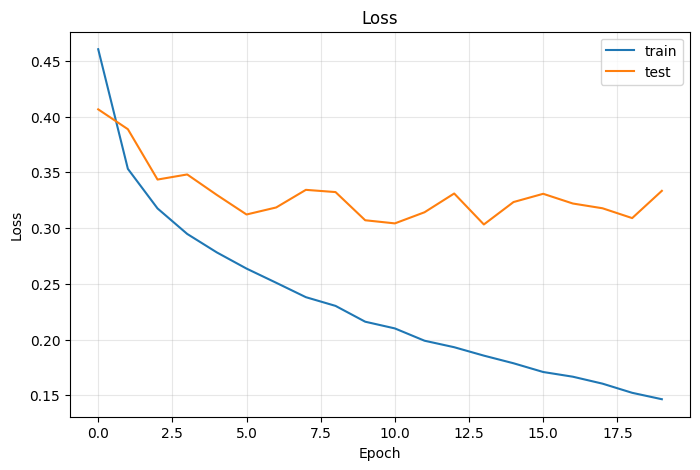

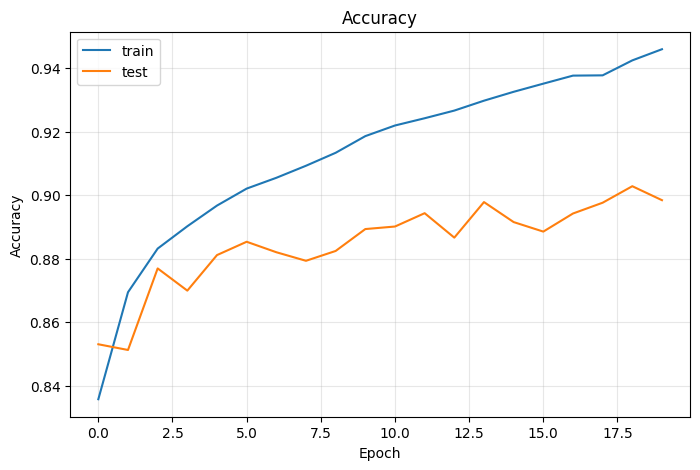

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(train_loss_history, label='train')
plt.plot(test_loss_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_acc_history, label='train')
plt.plot(test_acc_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Task 2: Overfit it.
Build a network that will overfit to this dataset. Demonstrate the overfitting in the appropriate way (e.g. plot loss and accurasy on train and test set w.r.t. network complexity).

*Note:* you also might decrease the size of `train` dataset to enforce the overfitting and speed up the computations.

In [22]:
class OverfittingNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, inp):
        out = self.model(inp)

        return out

In [23]:
torchsummary.summary(OverfittingNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                  [-1, 512]         401,920
              ReLU-3                  [-1, 512]               0
            Linear-4                  [-1, 256]         131,328
              ReLU-5                  [-1, 256]               0
            Linear-6                  [-1, 128]          32,896
              ReLU-7                  [-1, 128]               0
            Linear-8                   [-1, 64]           8,256
              ReLU-9                   [-1, 64]               0
           Linear-10                   [-1, 32]           2,080
             ReLU-11                   [-1, 32]               0
           Linear-12                   [-1, 16]             528
             ReLU-13                   [-1, 16]               0
           Linear-14                   

In [24]:
model = OverfittingNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_func = nn.NLLLoss()

n_epoch = 30
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

for epoch in range(n_epoch):
    model.train()
    train_loss, train_correct = 0., 0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        opt.zero_grad()
        predictions = model(x_batch)
        loss = loss_func(predictions, y_batch)
        loss.backward()
        opt.step()

        train_loss += loss.item() * len(x_batch)
        train_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    train_loss_history.append(train_loss / len(train_loader.dataset))
    train_acc_history.append(train_correct / len(train_loader.dataset))

    model.eval()
    test_loss, test_correct = 0., 0
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            predictions = model(x_batch)
            loss = loss_func(predictions, y_batch)

            test_loss += loss.item() * len(x_batch)
            test_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    test_loss_history.append(test_loss / len(test_loader.dataset))
    test_acc_history.append(test_correct / len(test_loader.dataset))

    print(f'epoch {epoch + 1:2d} | train loss {train_loss_history[-1]:.4f} | test loss {test_loss_history[-1]:.4f} '
          f'| train acc {train_acc_history[-1]:.4f} | test acc {test_acc_history[-1]:.4f}')

print(f'test accuracy: {test_acc_history[-1]:.4f}')

epoch  1 | train loss 0.7529 | test loss 0.5545 | train acc 0.7286 | test acc 0.8004
epoch  2 | train loss 0.4608 | test loss 0.4665 | train acc 0.8344 | test acc 0.8348
epoch  3 | train loss 0.3917 | test loss 0.4121 | train acc 0.8595 | test acc 0.8546
epoch  4 | train loss 0.3523 | test loss 0.3687 | train acc 0.8726 | test acc 0.8679
epoch  5 | train loss 0.3317 | test loss 0.3981 | train acc 0.8799 | test acc 0.8569
epoch  6 | train loss 0.3150 | test loss 0.3918 | train acc 0.8856 | test acc 0.8588
epoch  7 | train loss 0.2976 | test loss 0.3644 | train acc 0.8922 | test acc 0.8726
epoch  8 | train loss 0.2872 | test loss 0.3581 | train acc 0.8951 | test acc 0.8727
epoch  9 | train loss 0.2728 | test loss 0.3673 | train acc 0.8993 | test acc 0.8768
epoch 10 | train loss 0.2629 | test loss 0.3342 | train acc 0.9024 | test acc 0.8853
epoch 11 | train loss 0.2531 | test loss 0.3474 | train acc 0.9065 | test acc 0.8750
epoch 12 | train loss 0.2433 | test loss 0.3368 | train acc 0.910

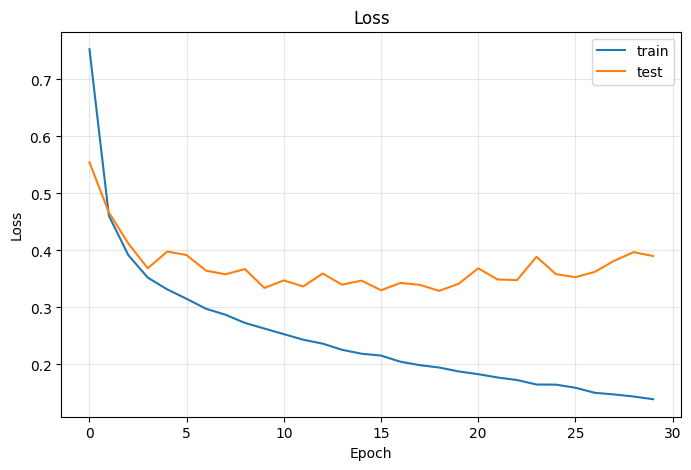

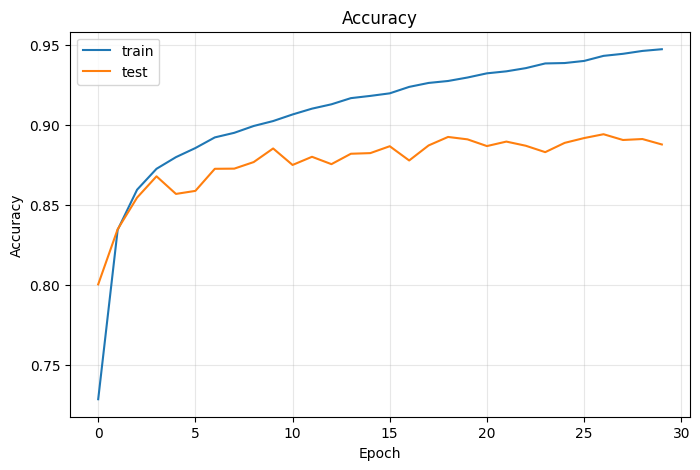

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(train_loss_history, label='train')
plt.plot(test_loss_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_acc_history, label='train')
plt.plot(test_acc_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Task 3: Fix it.
Fix the overfitted network from the previous step (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

In [26]:
class FixedNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 512),
            nn.BatchNorm1d(512, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.BatchNorm1d(16, eps=1e-3, momentum=0.1),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, num_classes),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, inp):
        out = self.model(inp)

        return out

In [27]:
torchsummary.summary(FixedNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                  [-1, 512]         401,920
       BatchNorm1d-3                  [-1, 512]           1,024
              ReLU-4                  [-1, 512]               0
           Dropout-5                  [-1, 512]               0
            Linear-6                  [-1, 256]         131,328
       BatchNorm1d-7                  [-1, 256]             512
              ReLU-8                  [-1, 256]               0
           Dropout-9                  [-1, 256]               0
           Linear-10                  [-1, 128]          32,896
      BatchNorm1d-11                  [-1, 128]             256
             ReLU-12                  [-1, 128]               0
          Dropout-13                  [-1, 128]               0
           Linear-14                   

In [28]:
model = FixedNeuralNetwork().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss_func = nn.NLLLoss()

n_epoch = 30
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

for epoch in range(n_epoch):
    model.train()
    train_loss, train_correct = 0., 0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        opt.zero_grad()
        predictions = model(x_batch)
        loss = loss_func(predictions, y_batch)
        loss.backward()
        opt.step()

        train_loss += loss.item() * len(x_batch)
        train_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    train_loss_history.append(train_loss / len(train_loader.dataset))
    train_acc_history.append(train_correct / len(train_loader.dataset))

    model.eval()
    test_loss, test_correct = 0., 0
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            predictions = model(x_batch)
            loss = loss_func(predictions, y_batch)

            test_loss += loss.item() * len(x_batch)
            test_correct += (predictions.argmax(dim=1) == y_batch).sum().item()

    test_loss_history.append(test_loss / len(test_loader.dataset))
    test_acc_history.append(test_correct / len(test_loader.dataset))

    print(f'epoch {epoch + 1:2d} | train loss {train_loss_history[-1]:.4f} | test loss {test_loss_history[-1]:.4f} '
          f'| train acc {train_acc_history[-1]:.4f} | test acc {test_acc_history[-1]:.4f}')

print(f'test accuracy: {test_acc_history[-1]:.4f}')

epoch  1 | train loss 1.0181 | test loss 0.5180 | train acc 0.7204 | test acc 0.8323
epoch  2 | train loss 0.6056 | test loss 0.4236 | train acc 0.8168 | test acc 0.8543
epoch  3 | train loss 0.5276 | test loss 0.3985 | train acc 0.8370 | test acc 0.8601
epoch  4 | train loss 0.4834 | test loss 0.4104 | train acc 0.8474 | test acc 0.8589
epoch  5 | train loss 0.4579 | test loss 0.3827 | train acc 0.8570 | test acc 0.8685
epoch  6 | train loss 0.4325 | test loss 0.3870 | train acc 0.8632 | test acc 0.8666
epoch  7 | train loss 0.4192 | test loss 0.3522 | train acc 0.8647 | test acc 0.8810
epoch  8 | train loss 0.3981 | test loss 0.3584 | train acc 0.8726 | test acc 0.8782
epoch  9 | train loss 0.3887 | test loss 0.3551 | train acc 0.8750 | test acc 0.8772
epoch 10 | train loss 0.3762 | test loss 0.3560 | train acc 0.8786 | test acc 0.8784
epoch 11 | train loss 0.3714 | test loss 0.3475 | train acc 0.8812 | test acc 0.8792
epoch 12 | train loss 0.3598 | test loss 0.3488 | train acc 0.885

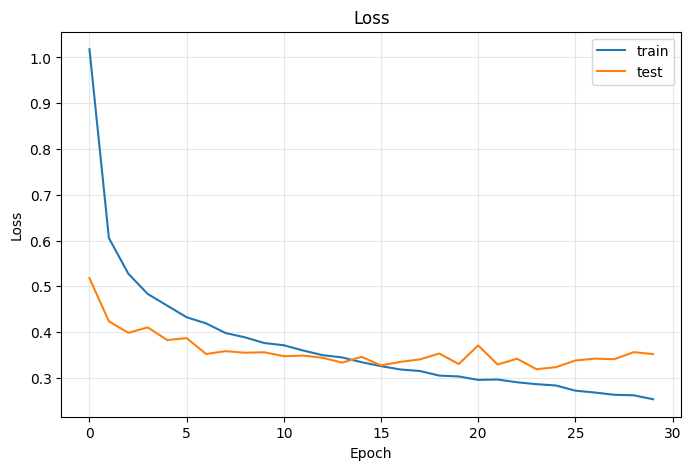

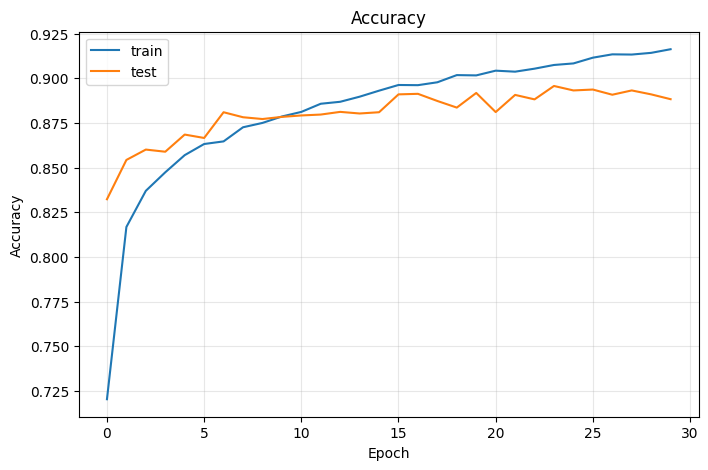

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(train_loss_history, label='train')
plt.plot(test_loss_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_acc_history, label='train')
plt.plot(test_acc_history, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Conclusions:
Для борьбы с переобучением в модель были добавлены Dropout с параметром 0.2 и батч-нормализация. Также в качестве оптимизатора был выбран AdamW, так как он использует weight decay для дополнительной регуляризации весов модели и помогает повысить устойчивость обучения.<br>
В итоге удалось снизить loss на тестовой выборке на 0.4 и слегка повысить accuracy.